# 96-Well Plate Expression Analysis — Summary

Summary of the plate-scale LC-MS screens (point mutants and Rosetta-designed precursors).

| Step | What it does |
|------|--------------|
| **Load** | Build `master_df` from every curated `*_manually_reviewed.pkl.gz` under `REPORTS_PATH`. |
| **Metadata refresh** | Optional one-time patch of plasmid names on already-reviewed groups. |
| **Modification ratios** | Best cut/charge per group, collapsed to a per-replicate `mod_ratio`. |
| **Point mutants** | Grouped alignment + bar plots for the point-mutant scan. |
| **Rosetta designs** | Bar plots and correlation of `mod_ratio` with Rosetta scores (`rosetta_modeling/selected_plp_sequences.xlsx`, not distributed). |
| **Export** | Writes the processed tables to `summary_data_files/`. |

> Edit `REPORTS_PATH` / `COMBINED_SI_PDF_PATH` in the configuration cell to point at your copy of the
> reports. Alignments require MUSCLE 5 (set the `MUSCLE_EXE` environment variable).

In [7]:
# Imports
import pandas as pd
import pickle
from pathlib import Path
from plotting_analysis_functions import *
import re

In [8]:
# --- 1. Pre-flight Compatibility Formatting ---
# NOTE: master-dataframe construction now lives in plotting_analysis_functions.py as
# build_master_dataframe_from_groups(), sourced directly from each group's curated
# ReplicateGroupResults (*_manually_reviewed.pkl.gz) via generate_modification_state_matrix(),
# rather than from the older '_CURATED_APPROVED.pkl' report format. See the next cell.

def prepare_dataframe_for_plotting(df: pd.DataFrame) -> pd.DataFrame:
    """
    Guarantees that columns and categorical fields perfectly match the exact
    expectations of your custom calculation and alignment plotting functions.
    """
    plot_df = df.copy()

    # 1. Map alternative column names to match your strict function expectations
    column_mappings = {
        'group_name': 'experiment_id',       # Maps group_name to experiment_id
        'peak_area': 'area',
        'target_sequence': 'peptide_sequence',
        'cluster_id': 'cut_id'
    }

    for old_col, new_col in column_mappings.items():
        if old_col in plot_df.columns and new_col not in plot_df.columns:
            plot_df[new_col] = plot_df[old_col]

    # Ensure 'target_sequence' exists (keep a copy of the unmodified peptide string)
    if 'target_sequence' not in plot_df.columns and 'peptide_sequence' in plot_df.columns:
        plot_df['target_sequence'] = plot_df['peptide_sequence']

    # 2. Since this data is already curated (only manually-approved peaks make it into
    # generate_modification_state_matrix()), treat everything as accepted 'Gold' if the
    # 'tier' column isn't explicitly present.
    if 'tier' not in plot_df.columns:
        plot_df['tier'] = 'Gold'

    # 3. Handle modification string conversions expected by your calculator loop
    if 'target_modifications' in plot_df.columns:
        # Standardize string format to look like your check: "{'unmodified': None}"
        plot_df['modification_state'] = plot_df['target_modifications'].astype(str).replace({
            "{'unmodified': None}": "{'unmodified': None}",
            "unmodified": "{'unmodified': None}"
        })
    elif 'modification_state' not in plot_df.columns:
        plot_df['modification_state'] = "{'unmodified': None}"

    # 4. Final safety fallbacks for columns that absolutely must exist
    required_cols = ['experiment_id', 'sample_id', 'peptide_sequence', 'cut_id', 'enzyme', 'precursor_name', 'area']
    for col in required_cols:
        if col not in plot_df.columns:
            plot_df[col] = 'N/A' if col != 'area' else 0.0

    return plot_df

In [9]:
# --- One-time step: refresh precursor_plasmid/precursor_name on already-reviewed groups ---
# For when you've fixed the input Excel and regenerated the per-sample MSExperiment pickles from
# it (e.g. by re-running main.py), and just need every already-manually-reviewed
# ReplicateGroupResults to pick up the corrected precursor_plasmid/precursor_name -- WITHOUT
# re-picking any peaks. Only those two attributes on each replicate's experiment object are
# patched in place; selected_peaks/found_peaks/target_peptides/raw spectral data are untouched.
#
# A timestamped backup of each original *_manually_reviewed.pkl.gz is written first (next to the
# original, under a `_metadata_backup_<timestamp>` subfolder), so this is fully reversible.
#
# NOTE: group_name (and therefore each group's folder/filename on disk) is deliberately NOT
# renamed here, even though precursor_plasmid was one of the values it was originally built from
# -- so a group whose precursor_plasmid changed will have correct in-object metadata but a
# folder/file name that still reads the OLD code. Rename those yourself afterward if you want them
# back in sync -- see ReplicateGroupResults.refresh_experiment_metadata()'s docstring in
# analysis_containers.py for the full reasoning.
#
# Safe to re-run, but only actually needs to run once per Excel fix -- comment out the call below
# once you've confirmed the printed old -> new changes look right.
from plotting_analysis_functions import find_group_result_files, refresh_group_experiment_metadata

REPORTS_PATH = r'PAPER_WRITING/output_reports_plates'
'''
refreshed_group_files = refresh_group_experiment_metadata(
    find_group_result_files(REPORTS_PATH)
)'''

'\nrefreshed_group_files = refresh_group_experiment_metadata(\n    find_group_result_files(REPORTS_PATH)\n)'

In [10]:
from pathlib import Path
from plotting_analysis_functions import build_master_dataframe_from_groups, get_ordered_source_files, natural_sort_key

# --- Configuration ---
REPORTS_PATH = r'PAPER_WRITING/output_reports_plates'

# Build the master DataFrame directly from every group's curated ReplicateGroupResults
# (one *_manually_reviewed.pkl.gz per group, produced by peak_reviewing_pipeline.py). Experiment
# metadata (required_grouping_cols, sample_id, precursor_name, peptide_sequence, core
# coordinates, etc.) is pulled straight from each replicate's MSExperiment object, so no separate
# metadata Excel merge is needed anymore.
master_df = build_master_dataframe_from_groups(REPORTS_PATH)
# we order in the following fashion:
miscellaneous_df = master_df[master_df["precursor_plasmid"].isin(["TJ-C-509", "TJ-C-510", "TJ-C-511", "TJ-C-512", "TJ-C-513", "TJ-C-514", "TJ-C-515", "TJ-C-516", "TJ-C-517", "TJ-C-518", "TJ-C-674", "TJ-C-677", "TJ-C-680", "TJ-C-683"])]
master_df = master_df[master_df["precursor_plasmid"].isin(["TJ-C-509", "TJ-C-510", "TJ-C-511", "TJ-C-512", "TJ-C-513", "TJ-C-514", "TJ-C-515", "TJ-C-516", "TJ-C-517", "TJ-C-518", "TJ-C-674", "TJ-C-677", "TJ-C-680", "TJ-C-683"]) == False]
master_df = master_df.sort_values(["experiment_id", "precursor_plasmid", "maturase_name"], key=natural_sort_key)

# The SI report order follows the same sort: get_ordered_source_files() walks master_df in this
# (now-sorted) row order and keeps the first occurrence of each group's source pickle path, since
# master_df has many rows per group (one per replicate x fragment_cut x charge x modification).
# This list is what drives page order for generate_si_reports()/generate_and_combine_si_reports()
# below -- both take it verbatim and don't do any sorting of their own, so the PDF page order,
# page numbers, and combined-document order all end up matching this list exactly.
ordered_source_file_list = get_ordered_source_files(
    master_df, sort_cols=["experiment_id", "precursor_plasmid", "maturase_name"]
)
print(f"{len(ordered_source_file_list)} group(s) ordered for SI report generation.")
import plotting_analysis_functions
# --- Generate all SI data PDF reports, then combine them into one document ---
# For every group's curated ReplicateGroupResults, in exactly the order given by
# ordered_source_file_list (built in the master_df cell above):
#   1. Builds a GroupedExperiments via GroupedExperiments.from_replicate_group_results().
#   2. Picks the single best (fragment_cut, charge) via select_best_cut_charge() -- fewest stub
#      replicates first, then highest average area, then highest average quality_score (mirrors
#      extract_best_cut_charge()'s priority above).
#   3. Plots only the manually curated (selected_peaks) peaks at that cut/charge; replicates with
#      no curated selection for a given modification state are listed in the summary table as
#      stubs but are not plotted.
#   4. Writes one single-page, high-resolution A4 PDF per group -- with headers/footers, a
#      sequential page number matching its position in ordered_source_file_list, and a
#      page-order-matching filename -- into the SAME folder as that group's pickle (not a
#      separate output tree).
# Finally, merges every generated PDF, in that same order, into one combined document at
# COMBINED_SI_PDF_PATH.
from plotting_analysis_functions import generate_and_combine_si_reports

COMBINED_SI_PDF_PATH = r'D:\Spliceotide_Data_Analysis\output_reports_plates\SI_reports\combined_SI_report.pdf'

combined_si_pdf_path = plotting_analysis_functions.generate_and_combine_simple_si_reports(
    ordered_source_file_list, COMBINED_SI_PDF_PATH, appendix_name="SI Appendix B", layout="beta", rt_range=(3,7), break_axis=True, footer=True
)

Found 140 manually reviewed group file(s) under: PAPER_WRITING/output_reports_plates
Successfully loaded ReplicateGroupResults from: PAPER_WRITING\output_reports_plates\point_mutants_mutant_10_HypX-HypY_TJ-C-689_24_TEV\point_mutants_mutant_10_HypX-HypY_TJ-C-689_24_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: PAPER_WRITING\output_reports_plates\point_mutants_mutant_10_PlpX-PlpY_TJ-C-559_24_TEV\point_mutants_mutant_10_PlpX-PlpY_TJ-C-559_24_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: PAPER_WRITING\output_reports_plates\point_mutants_mutant_11_HypX-HypY_TJ-C-689_24_TEV\point_mutants_mutant_11_HypX-HypY_TJ-C-689_24_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: PAPER_WRITING\output_reports_plates\point_mutants_mutant_11_PlpX-PlpY_TJ-C-559_24_TEV\point_mutants_mutant_11_PlpX-PlpY_TJ-C-559_24_TEV_manually_reviewed.pkl.gz
Successfully loaded ReplicateGroupResults from: PAPER_WRITING\output_reports_pl

In [11]:
from plotting_analysis_functions import extract_best_cut_charge, collapse_modification_replicates

# --- 2. Data Preparation Chain ---
# Step A: For every experimental group, pick the single best (cut, charge) combination
# (highest average quality_score across replicates/modifications, then highest average area).
best_cut_charge_df = extract_best_cut_charge(master_df)

# Step B: Collapse each replicate down to its unmodified peptide, computing
# total_modification_ratio (aliased as mod_ratio) = unmodified area / overall_signal_intensity.
processed_ratios_df = collapse_modification_replicates(best_cut_charge_df)

print(f"Summary data ready. Calculated modification ratios for {len(processed_ratios_df)} features.")

[collapse_modification_replicates] 18 of 479 replicate(s) have an undetected (stub) unmodified peptide -> mod_ratio set to NaN (cannot distinguish full conversion from a missed peak).
Summary data ready. Calculated modification ratios for 479 features.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


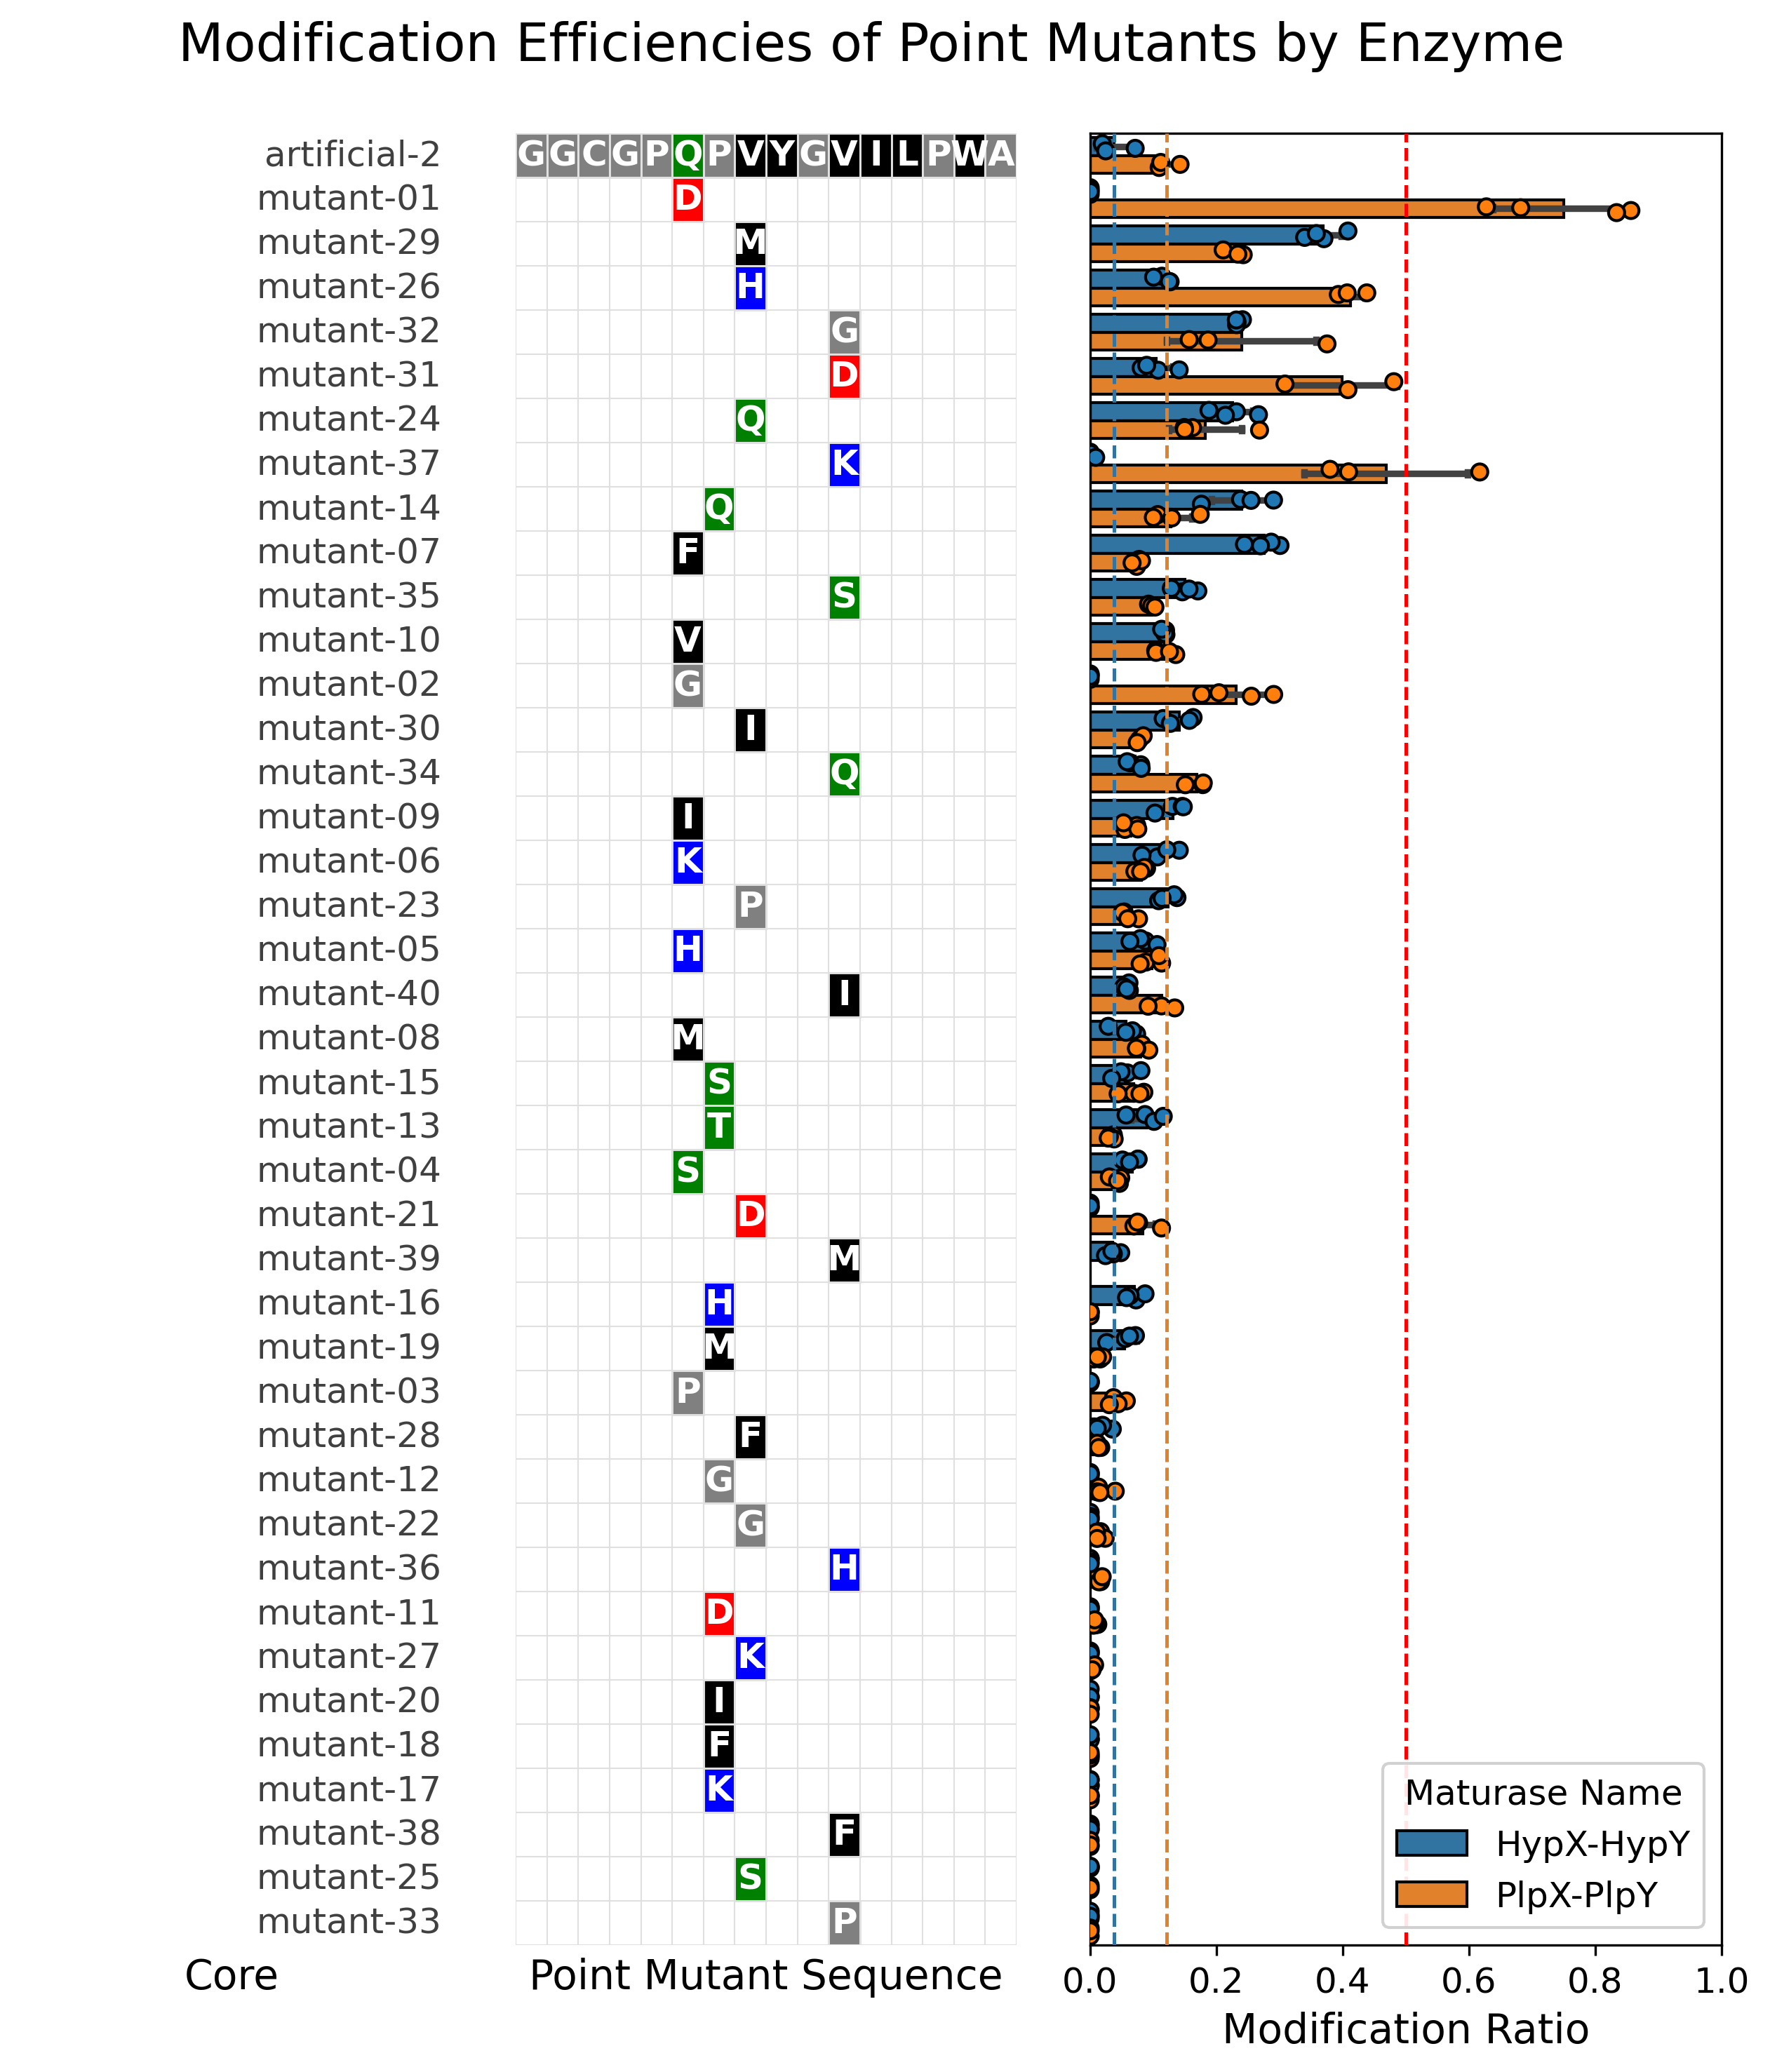

In [12]:
# matplotlib inline
import re
point_mutant_comparison = processed_ratios_df[processed_ratios_df["experiment_id"] == "point_mutants"]


# we plot
point_mutant_plot = point_mutant_comparison[
    (point_mutant_comparison["precursor_plasmid"].str.contains("mutant")) |
    (point_mutant_comparison["precursor_plasmid"] == "TJ-C-706") |
    (point_mutant_comparison["precursor_plasmid"] == "TJ-C-710")
]
# if precursor_plasmid is 706 or 710 then precursor_name is artificial-2
# else it is the same as precursor_plasmid but with _ replaced by -
point_mutant_plot["precursor_name"] = np.where(
    point_mutant_plot["precursor_plasmid"].isin(["TJ-C-706", "TJ-C-710"]),
    "artificial-2",
    point_mutant_plot["precursor_plasmid"].str.replace("precursor_", "mutant-"))

# we make the labels a bit prettier

def clean_mutant_name(name):
    # Check if the value is a string and starts with 'mutant_'
    if isinstance(name, str) and name.startswith('mutant_'):
        # Split into 'mutant' and the number
        prefix, number = name.split('_')
        # Reconstruct the string with a hyphen and a 2-digit zero-padded number
        return f"mutant-{int(number):02d}"

    # Return the original name if it doesn't match (e.g., 'artificial-2')
    return name

# Apply the function to the target column
point_mutant_plot['precursor_name'] = point_mutant_plot['precursor_name'].apply(clean_mutant_name)

REFERENCE_SEQUENCE = "GGCGPQPVYGVILPWA"
create_grouped_alignment_plot(
    point_mutant_plot,
    ref_sequence = REFERENCE_SEQUENCE,
    metadata_cols= ['precursor_name'],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    preset = 'poster',
    use_alignment = True,
    drop_identical = True,
    sequence_column = "target_sequence",
    metatitle="Core",
    seqtitle="Point Mutant Sequence",
    suptitle="Modification Efficiencies of Point Mutants by Enzyme",
    savepath=r"summary_data_files/point_mutant_plates_plot_poster.eps",
    plot_baseline=True,
    plot_midline=True
)


C:\Users\jordant\AppData\Local\Temp\ipykernel_30224\1738981931.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rosetta_comparison["precursor_name"] = np.where(
C:\Users\jordant\AppData\Local\Temp\ipykernel_30224\1738981931.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rosetta_comparison['precursor_name'] = rosetta_comparison['precursor_name'].apply(clean_mutant_name)
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


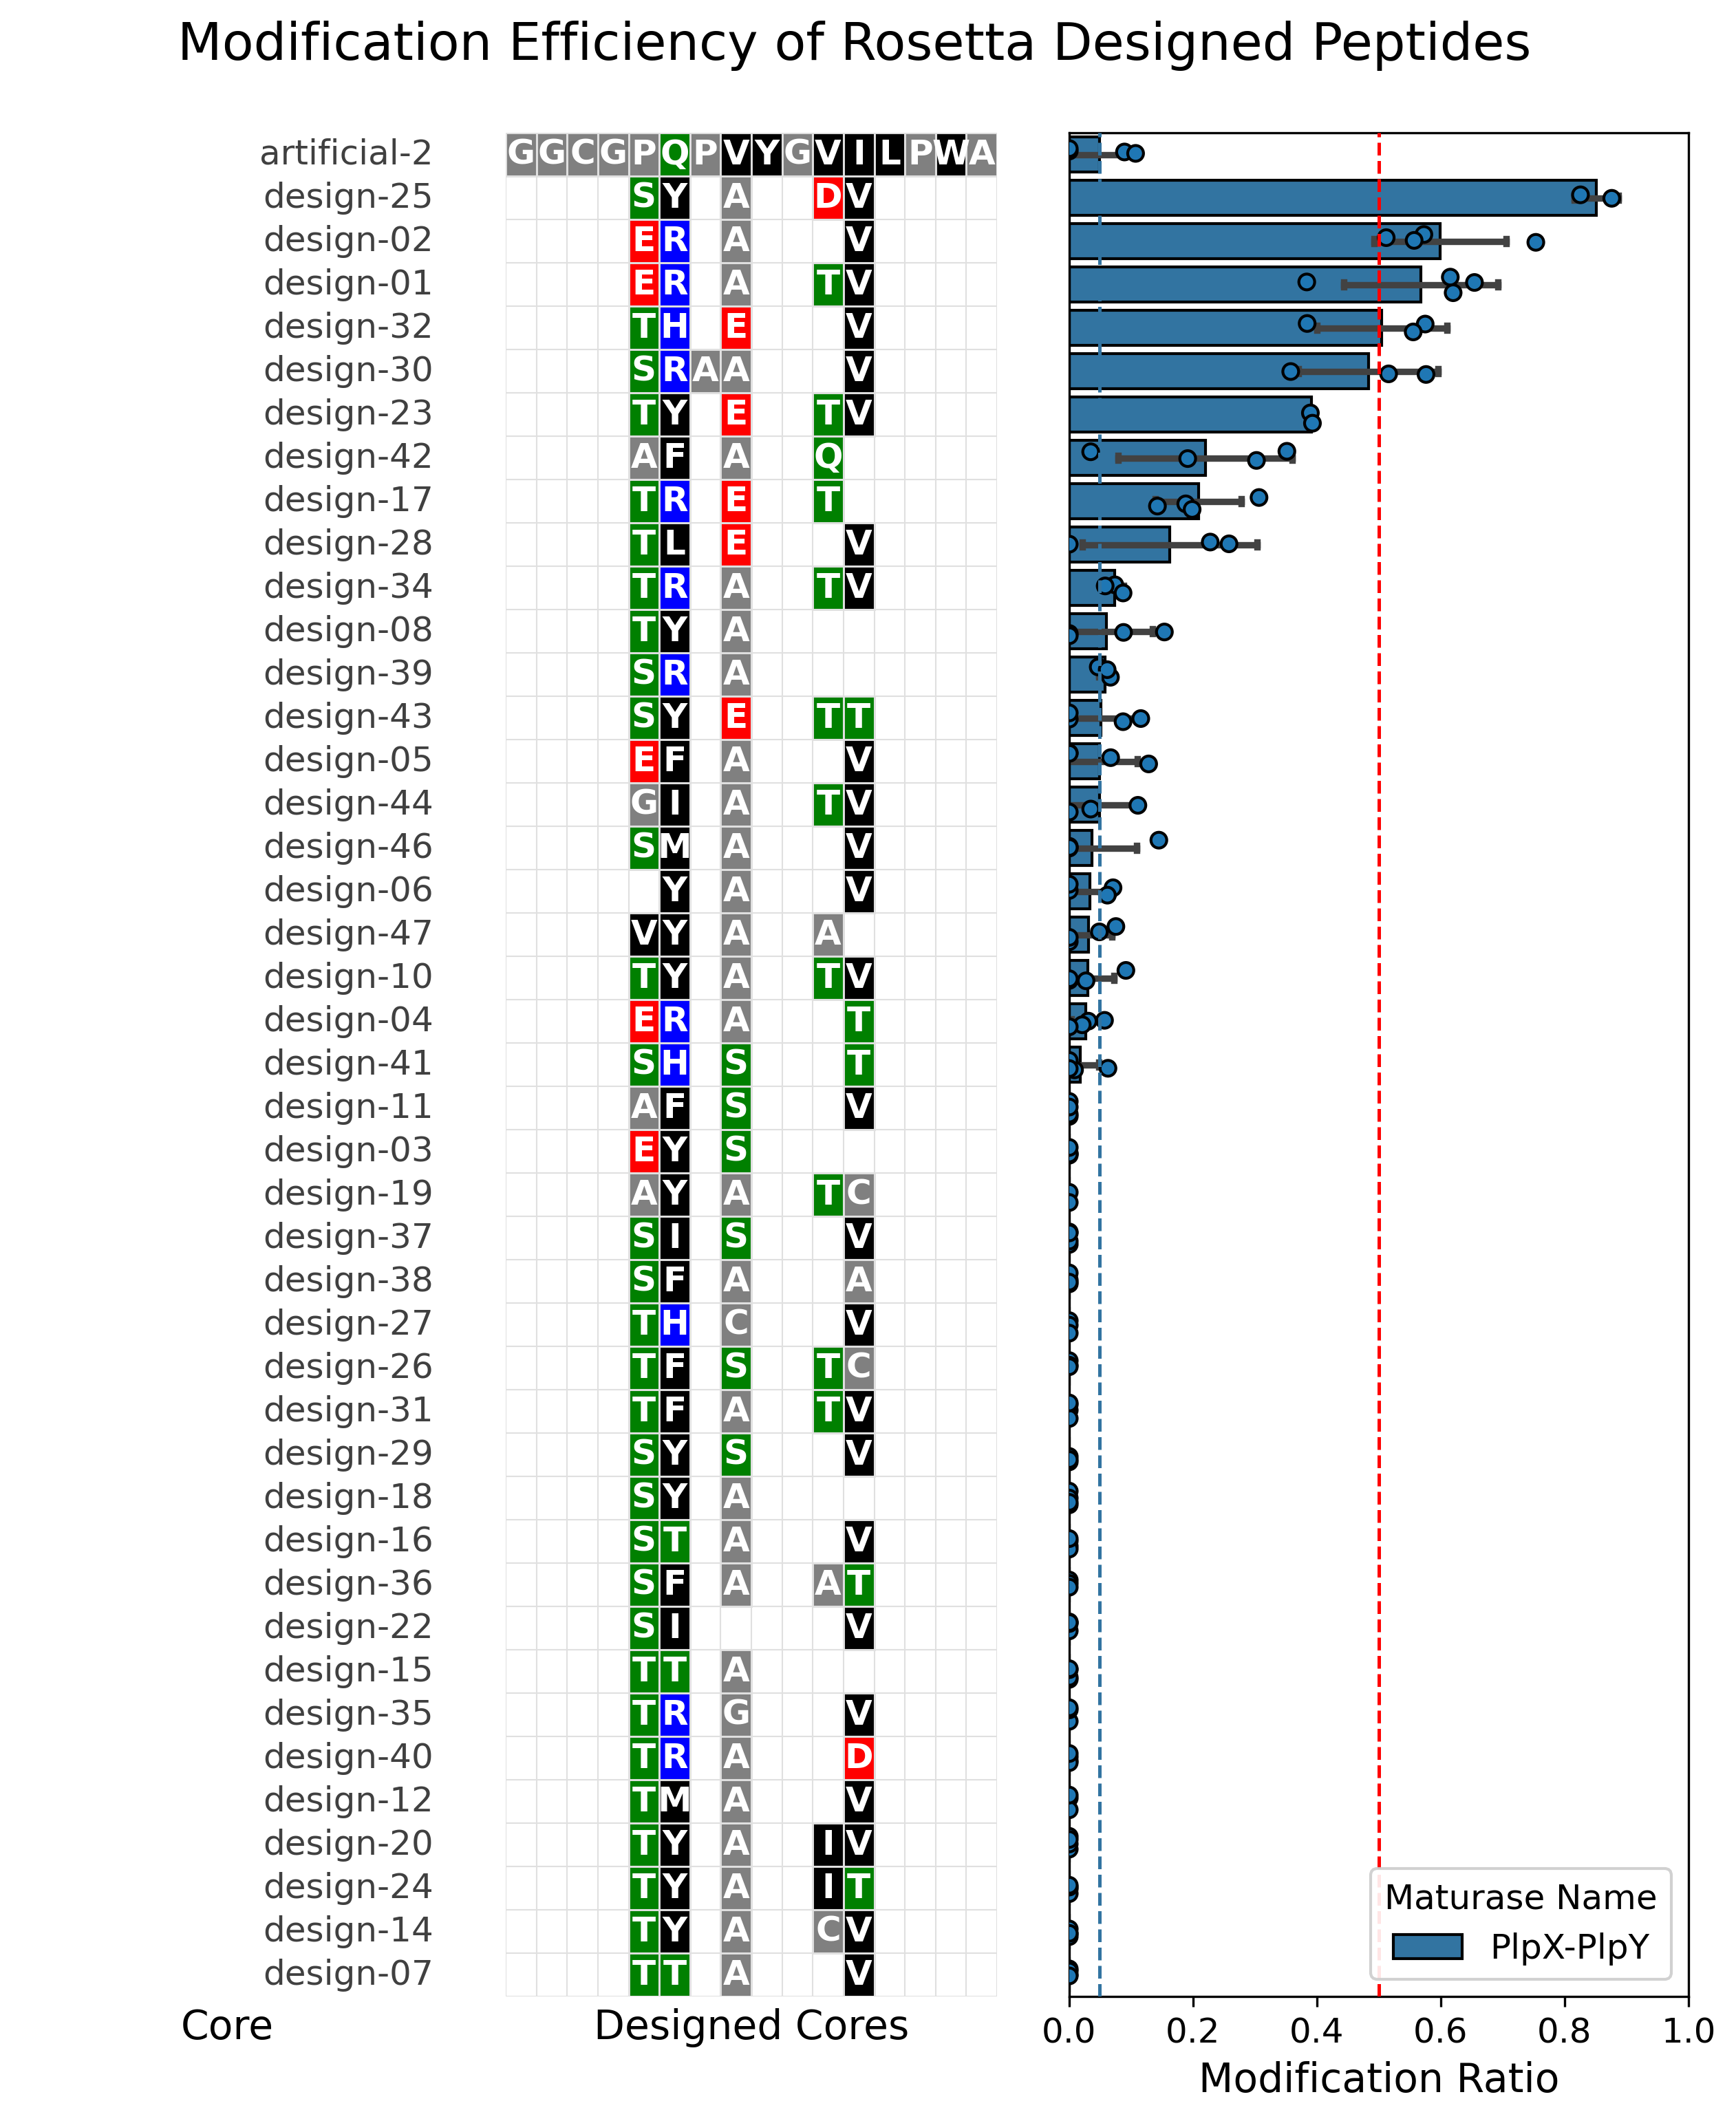

In [13]:

rosetta_comparison = processed_ratios_df[processed_ratios_df["experiment_id"] == "rosetta_top_47"]
rosetta_comparison["precursor_name"] = np.where(
    rosetta_comparison["precursor_plasmid"].isin(["TJ-C-710"]),
    "artificial-2",
    rosetta_comparison["precursor_plasmid"].str.replace("precursor_", "designed_"))

def clean_mutant_name(name):
    # Check if the value is a string and starts with 'mutant_'
    if isinstance(name, str) and name.startswith('design_'):
        # Split into 'mutant' and the number
        prefix, number = name.split('_')
        # Reconstruct the string with a hyphen and a 2-digit zero-padded number
        return f"design-{int(number):02d}"

    # Return the original name if it doesn't match (e.g., 'artificial-2')
    return name

# Apply the function to the target column
rosetta_comparison['precursor_name'] = rosetta_comparison['precursor_name'].apply(clean_mutant_name)

# If your dataset spans multiple distinct enzymes (e.g., different maturities or conditions):
REFERENCE_SEQUENCE = "GGCGPQPVYGVILPWA"

REFERENCE_SEQUENCE = "GGCGPQPVYGVILPWA"
create_grouped_alignment_plot(
    rosetta_comparison,
    ref_sequence = REFERENCE_SEQUENCE,
    metadata_cols= ['precursor_name'],
    color_scheme_name= "hydrophobicity",
    show_ddg= False,
    preset = 'poster',
    use_alignment = True,
    drop_identical = True,
    sequence_column = "peptide_sequence_meta",
    metatitle="Core",
    seqtitle="Designed Cores",
    suptitle="Modification Efficiency of Rosetta Designed Peptides",
    savepath=r"summary_data_files/rosetta_designs_plates_plot.eps",
    plot_baseline=True,
    plot_midline=True
)


In [14]:
# we load the rosetta data
rosetta_sim_df = pd.read_excel("rosetta_modeling/selected_plp_sequences.xlsx")
# we merge the rosetta_sim_df to the rosetta_comparison df using a merge on the sequence and target_sequence

agg_rosetta = rosetta_comparison.groupby("peptide_sequence_meta")["mod_ratio"].agg("mean")
merged_score_rosetta = pd.merge(agg_rosetta, rosetta_sim_df, left_on="peptide_sequence_meta", right_on="sequence", how="left")

import scipy.stats as stats
from statsmodels.stats.multitest import multipletests
score_col_names = ["total_score", "energy_peptide", "fa_atr", "fa_dun", "fa_sol", "ligand_score_1X", "ligand_score_2X", "ligand_score_3X", "ligand_score_4X", "packstat", "sasa", "sc", "sc_int_area"]

results = []

# 2. Calculate Spearman correlation for each score
for feature in score_col_names:
    # Drop NaNs to ensure the correlation function doesn't crash
    valid_data = merged_score_rosetta[["mod_ratio", feature]].dropna()

    if len(valid_data) > 2:  # Need at least 3 points to correlate
        rho, p_val = stats.spearmanr(valid_data[feature], valid_data["mod_ratio"])
        results.append({
            'rosetta_metric': feature,
            'spearman_rho': rho,
            'p_value': p_val,
            'n_variants': len(valid_data)
        })

results_df = pd.DataFrame(results)
# 3. Correct for multiple hypothesis testing (Benjamini-Hochberg FDR)
results_df['fdr_adjusted_p'] = multipletests(results_df['p_value'], method='fdr_bh')[1]

# Sort by the strongest absolute correlation
results_df['abs_rho'] = results_df['spearman_rho'].abs()
results_df = results_df.sort_values(by='abs_rho', ascending=False).drop(columns=['abs_rho'])

# View the top correlations
print(results_df.head(10))



     rosetta_metric  spearman_rho   p_value  n_variants  fdr_adjusted_p
12      sc_int_area      0.432468  0.004232          42        0.055022
3            fa_dun      0.352090  0.022213          42        0.087026
1    energy_peptide     -0.343601  0.025887          42        0.087026
4            fa_sol      0.341696  0.026777          42        0.087026
2            fa_atr     -0.312074  0.044221          42        0.114974
6   ligand_score_2X     -0.232917  0.137697          42        0.298343
5   ligand_score_1X      0.198262  0.208159          42        0.386580
10             sasa      0.139363  0.378736          42        0.615445
11               sc     -0.118191  0.455990          42        0.646406
7   ligand_score_3X     -0.107693  0.497236          42        0.646406


In [15]:
# we save the processed ratios df to a excel file for further analysis inside the summary_data_files folder
processed_ratios_df.to_excel("summary_data_files/96_well_plates_processed_ratios_df.xlsx", index=False)
# we save the point_mutant_comparison df to a excel file for further analysis inside the summary_data_files folder
point_mutant_comparison.to_excel("summary_data_files/96_well_plates_point_mutant_comparison.xlsx", index=False)
# we save the rosetta_comparison df to a excel file for further analysis inside the summary_data_files folder
rosetta_comparison.to_excel("summary_data_files/96_well_plates_rosetta_comparison.xlsx", index=False)

In [16]:
point_mutant_agg = point_mutant_comparison.groupby(["maturase_name", "peptide_sequence_meta"])["mod_ratio"].agg("mean")
point_mutant_agg.to_excel("summary_data_files/96_well_plates_point_mutant_agg.xlsx")

In [17]:
# we analyze some exceptions/weird cases by hand

with open(r"D:\Spliceotide_Data_Analysis\output_reports_plates\rosetta_top_47\rosetta_top_47_precursor_5_PlpX-PlpY_TJ-C-599_24_TEV\rosetta_top_47_precursor_5_PlpX-PlpY_TJ-C-599_24_TEV_master_pipeline_output.pkl", "rb") as fp:
    data_rosetta_peptide_05 = pickle.load(fp)


FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Spliceotide_Data_Analysis\\output_reports_plates\\rosetta_top_47\\rosetta_top_47_precursor_5_PlpX-PlpY_TJ-C-599_24_TEV\\rosetta_top_47_precursor_5_PlpX-PlpY_TJ-C-599_24_TEV_master_pipeline_output.pkl'